# Etapa 4 — Treinamento do modelo

Objetivo: prever o prazo de entrega (`y`, em dias) com informações conhecidas no ato da compra.

- **Dados:** os mesmos da etapa 2 (`construir_dataset`), com a mesma divisão 80/20 (`random_state=42`).
  O treino não tem pedidos acima de 60 dias; o teste mantém todos e as métricas saem em "todos" e "até 60 dias".
- **Validação:** validação cruzada de 5 folds (KFold) **só no treino**. O teste é usado uma única vez, no final.
- **Pré-processamento:** o `ColumnTransformer` da etapa 2 fica **dentro** do `Pipeline` de cada modelo. Assim, em cada fold,
  imputação, padronização e `TargetEncoder` são ajustados só com o treino do fold (sem vazamento).
- **Modelos:** Ridge (linear), Árvore de decisão, KNN (instâncias), Random Forest e Gradient Boosting (ensembles).
- **Hiperparâmetros:** `GridSearchCV` nos modelos leves e `RandomizedSearchCV` nos ensembles, otimizando o **RMSE**.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))
from app.features import carregar_tabelas, construir_dataset
from app.modelos import (
    LIMITE_CAUDA_DIAS, SEED, avaliar_no_teste, definir_buscas, dividir_dados, executar_busca, resumo_cv,
)

DATA_DIR = RAIZ / 'data' / 'olist'
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)

## 1. Dados e divisão treino/teste

Reaproveitamos `construir_dataset` e a decisão da etapa 2: treino sem pedidos com `y > 60`, teste completo.
A categoria do produto entra com `TargetEncoder` (decisão da etapa 2).

In [2]:
tabelas = carregar_tabelas(DATA_DIR)
df = construir_dataset(tabelas)
X_treino, y_treino, X_teste, y_teste, prazo_estimado_teste = dividir_dados(df)

print(f'Treino: {X_treino.shape} | Teste: {X_teste.shape}')
print(f'Pedidos do teste acima de {LIMITE_CAUDA_DIAS} dias: {(y_teste > LIMITE_CAUDA_DIAS).sum()}')
print(f'Features: {list(X_treino.columns)}')

Treino: (76927, 19) | Teste: (19294, 19)
Pedidos do teste acima de 60 dias: 57
Features: ['frete_total', 'preco_total', 'peso_total_g', 'volume_total_cm3', 'dist_km', 'n_itens', 'customer_lat', 'customer_lng', 'seller_lat', 'seller_lng', 'mes_sin', 'mes_cos', 'dia_semana', 'hora', 'mesmo_estado', 'varios_vendedores', 'customer_state', 'seller_state', 'categoria']


## 2. Referências para comparar

Antes de otimizar, três referências simples no teste: prever sempre a média do treino, o prazo estimado
que a própria Olist mostra ao cliente (`prazo_estimado`, que **não** entra no modelo) e o baseline da etapa 2
(`HistGradientBoostingRegressor` com parâmetros padrão).

In [3]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from app.features import criar_preprocessador

media = DummyRegressor(strategy='mean').fit(X_treino, y_treino)
baseline = Pipeline([('prep', criar_preprocessador()),
                     ('modelo', HistGradientBoostingRegressor(random_state=SEED))]).fit(X_treino, y_treino)

linhas = []
linhas += avaliar_no_teste('Prever a média', media.predict(X_teste), y_teste)
linhas += avaliar_no_teste('Prazo estimado da Olist', prazo_estimado_teste, y_teste)
linhas += avaliar_no_teste('Baseline HGB (padrão)', baseline.predict(X_teste), y_teste)
referencias = pd.DataFrame(linhas)
referencias

,modelo,recorte,MAE,RMSE,R²
0,Prever a média,todos os pedidos,6.371,9.314,-0.000
1,Prever a média,até 60 dias,6.183,8.410,-0.000
2,Prazo estimado da Olist,todos os pedidos,12.704,14.974,-1.585
3,Prazo estimado da Olist,até 60 dias,12.583,14.640,-2.031
4,Baseline HGB (padrão),todos os pedidos,4.613,7.472,0.356
5,Baseline HGB (padrão),até 60 dias,4.436,6.463,0.409


O prazo estimado da Olist é uma previsão conservadora (quase sempre acima do prazo real), por isso o RMSE dele é alto.
Ele serve de termo de comparação, não como modelo.

## 3. Ajuste de hiperparâmetros

Cada modelo recebe uma busca com validação cruzada de 5 folds sobre o treino, otimizando o RMSE:

| Modelo | Busca | Por quê |
|---|---|---|
| Ridge | `GridSearchCV` | um único hiperparâmetro (`alpha`), grade pequena |
| Árvore de decisão | `GridSearchCV` | profundidade e tamanho mínimo da folha |
| KNN | `GridSearchCV` | número de vizinhos e ponderação |
| Random Forest | `RandomizedSearchCV` | espaço grande e treino caro: amostra 12 combinações |
| Gradient Boosting (HGB) | `RandomizedSearchCV` | espaço grande: amostra 25 combinações |

In [4]:
buscas = definir_buscas()
N_ITER = {'Random Forest': 12, 'Gradient Boosting (HGB)': 25}
CV = {'Random Forest': 3}  # RF é o modelo mais caro; 3 folds mantêm o tempo razoável

resultados_busca = {}
for nome, (tipo, pipeline, espaco) in buscas.items():
    inicio = time.time()
    busca = executar_busca(tipo, pipeline, espaco, X_treino, y_treino,
                           cv=CV.get(nome, 5), n_iter=N_ITER.get(nome, 15))
    resultados_busca[nome] = busca
    print(f'{nome:26s} {tipo:6s} | RMSE val {-busca.best_score_:.3f} | {time.time() - inicio:6.0f}s | {busca.best_params_}')

Ridge                      grid   | RMSE val 6.833 |     22s | {'modelo__alpha': 1}


Árvore de decisão          grid   | RMSE val 6.758 |     20s | {'modelo__max_depth': 12, 'modelo__min_samples_leaf': 200}


KNN                        grid   | RMSE val 6.743 |    616s | {'modelo__n_neighbors': 50, 'modelo__weights': 'distance'}


Random Forest              random | RMSE val 6.494 |    423s | {'modelo__max_depth': 17, 'modelo__max_features': 0.5, 'modelo__max_samples': 0.8, 'modelo__min_samples_leaf': 6, 'modelo__n_estimators': 291}


Gradient Boosting (HGB)    random | RMSE val 6.393 |    308s | {'modelo__l2_regularization': np.float64(0.029204338471814112), 'modelo__learning_rate': np.float64(0.06877172495876586), 'modelo__max_iter': 274, 'modelo__max_leaf_nodes': 58, 'modelo__min_samples_leaf': 117}


### Combinações testadas

As cinco melhores de cada modelo, com o RMSE de validação, o desvio entre folds e o RMSE no próprio treino
(a diferença entre os dois mostra o sobreajuste).

In [5]:
for nome, busca in resultados_busca.items():
    print(f'\n=== {nome} ({len(busca.cv_results_["params"])} combinações) ===')
    display(resumo_cv(busca).head(5).rename(columns=lambda c: c.replace('param_modelo__', '')))


=== Ridge (6 combinações) ===


,RMSE_val,desvio_val,RMSE_treino,alpha
2,6.833,0.033,6.822,1.000
1,6.833,0.033,6.822,0.100
0,6.833,0.033,6.822,0.010
3,6.833,0.033,6.823,10.000
4,6.838,0.033,6.828,100.000



=== Árvore de decisão (12 combinações) ===


,RMSE_val,desvio_val,RMSE_treino,max_depth,min_samples_leaf
11,6.758,0.023,6.632,12,200
10,6.775,0.018,6.429,12,50
7,6.784,0.030,6.660,8,50
6,6.791,0.033,6.626,8,10
8,6.797,0.030,6.713,8,200



=== KNN (8 combinações) ===


,RMSE_val,desvio_val,RMSE_treino,n_neighbors,weights
5,6.743,0.033,3.963,50,distance
3,6.760,0.035,3.179,25,distance
4,6.764,0.032,6.630,50,uniform
7,6.766,0.031,4.698,100,distance
2,6.781,0.033,6.509,25,uniform



=== Random Forest (12 combinações) ===


,RMSE_val,desvio_val,RMSE_treino,max_depth,max_features,max_samples,min_samples_leaf,n_estimators
4,6.494,0.037,5.305,17,0.500,0.800,6,291
5,6.555,0.032,6.145,17,0.300,0.500,16,157
1,6.572,0.031,6.266,18,0.300,0.500,23,174
2,6.593,0.031,6.359,16,0.300,0.800,44,251
6,6.606,0.031,6.396,11,0.300,0.800,29,148



=== Gradient Boosting (HGB) (25 combinações) ===


,RMSE_val,desvio_val,RMSE_treino,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf
6,6.393,0.037,5.845,0.029,0.069,274,58,117
12,6.393,0.030,5.941,0.050,0.035,359,61,155
14,6.398,0.033,5.880,0.020,0.094,351,47,91
10,6.400,0.019,5.921,0.008,0.038,363,54,44
5,6.402,0.029,5.955,0.015,0.105,269,35,197


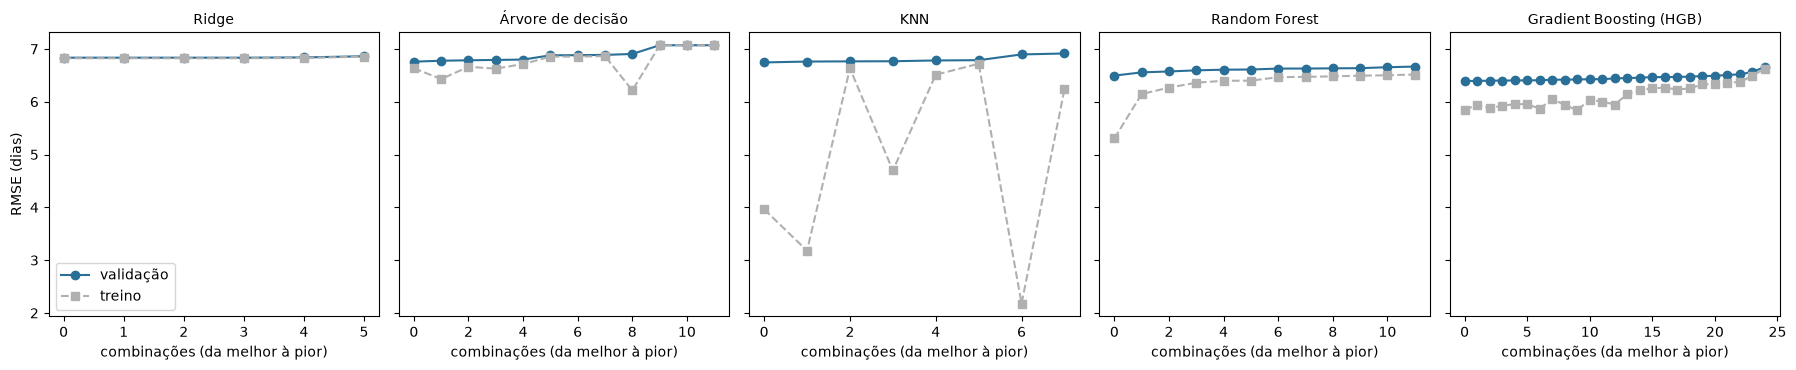

In [6]:
# Gráfico: RMSE de validação das combinações testadas, por modelo.
fig, eixos = plt.subplots(1, len(resultados_busca), figsize=(18, 3.8), sharey=True)
for eixo, (nome, busca) in zip(eixos, resultados_busca.items()):
    r = resumo_cv(busca)
    eixo.plot(range(len(r)), r['RMSE_val'].to_numpy(), 'o-', color='#2a6f97', label='validação')
    eixo.plot(range(len(r)), r['RMSE_treino'].to_numpy(), 's--', color='#b0b0b0', label='treino')
    eixo.set_title(nome, fontsize=10)
    eixo.set_xlabel('combinações (da melhor à pior)')
eixos[0].set_ylabel('RMSE (dias)')
eixos[0].legend()
fig.tight_layout()
plt.show()

## 4. Avaliação no teste

Cada modelo já foi reajustado com todo o treino na melhor combinação (`refit=True`). O teste foi usado só agora.

In [7]:
linhas = []
previsoes = {}
for nome, busca in resultados_busca.items():
    previsoes[nome] = busca.predict(X_teste)
    linhas += avaliar_no_teste(nome, previsoes[nome], y_teste)
tabela_teste = pd.DataFrame(linhas)
comparacao = pd.concat([referencias, tabela_teste], ignore_index=True)
comparacao.pivot(index='modelo', columns='recorte', values=['MAE', 'RMSE', 'R²']).sort_values(
    ('RMSE', 'todos os pedidos'))

MAE                         RMSE                           R²                 
recorte                 até 60 dias todos os pedidos até 60 dias todos os pedidos até 60 dias todos os pedidos
modelo                                                                                                        
Gradient Boosting (HGB)       4.350            4.525       6.379            7.390       0.425            0.370
Baseline HGB (padrão)         4.436            4.613       6.463            7.472       0.409            0.356
Random Forest                 4.464            4.640       6.503            7.509       0.402            0.350
KNN                           4.647            4.826       6.748            7.737       0.356            0.310
Árvore de decisão             4.681            4.859       6.770            7.757       0.352            0.306
Ridge                         4.788            4.966       6.836            7.821       0.339            0.295
Prever a média                6.183            6.371       8.410            9.314      -0.000           -0.000
Prazo estimado da Olist      12.583           12.704      14.640           14.974      -2.031           -1.585

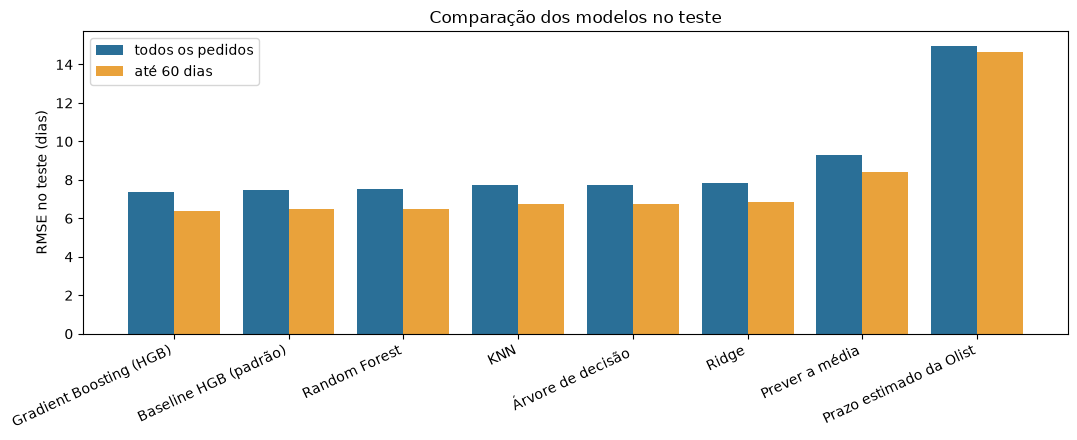

In [8]:
# Gráfico: RMSE no teste, todos os pedidos x até 60 dias.
ordem = comparacao[comparacao['recorte'] == 'todos os pedidos'].sort_values('RMSE')['modelo'].tolist()
fig, eixo = plt.subplots(figsize=(11, 4.5))
posicao = np.arange(len(ordem))
for deslocamento, recorte, cor in [(-0.2, 'todos os pedidos', '#2a6f97'), (0.2, f'até {LIMITE_CAUDA_DIAS} dias', '#e9a23b')]:
    valores = [comparacao[(comparacao['modelo'] == m) & (comparacao['recorte'] == recorte)]['RMSE'].iloc[0] for m in ordem]
    eixo.bar(posicao + deslocamento, valores, width=0.4, label=recorte, color=cor)
eixo.set_xticks(posicao, ordem, rotation=25, ha='right')
eixo.set_ylabel('RMSE no teste (dias)')
eixo.set_title('Comparação dos modelos no teste')
eixo.legend()
fig.tight_layout()
plt.show()

## 5. Análise do melhor modelo

Melhor modelo no teste (RMSE, todos os pedidos): Gradient Boosting (HGB)
Parâmetros: {'modelo__l2_regularization': np.float64(0.029204338471814112), 'modelo__learning_rate': np.float64(0.06877172495876586), 'modelo__max_iter': 274, 'modelo__max_leaf_nodes': 58, 'modelo__min_samples_leaf': 117}


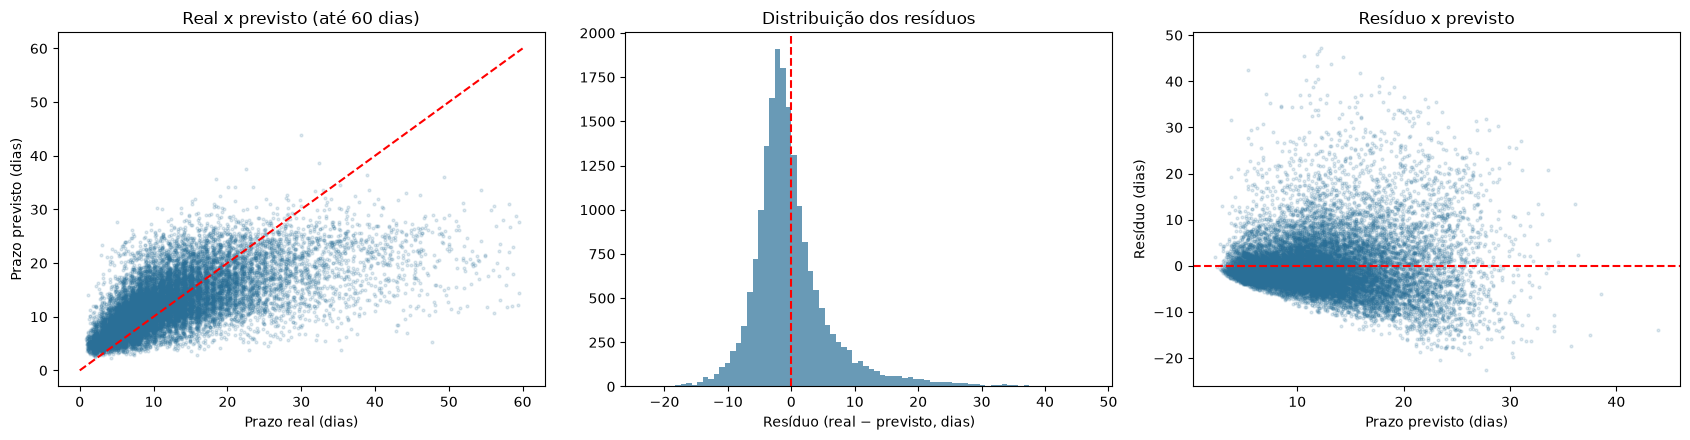

In [9]:
melhor_nome = (tabela_teste[tabela_teste['recorte'] == 'todos os pedidos']
               .sort_values('RMSE').iloc[0]['modelo'])
melhor = resultados_busca[melhor_nome]
print(f'Melhor modelo no teste (RMSE, todos os pedidos): {melhor_nome}')
print(f'Parâmetros: {melhor.best_params_}')

previsto = previsoes[melhor_nome]
residuo = y_teste.to_numpy() - previsto
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.5))

ate_limite = (y_teste <= LIMITE_CAUDA_DIAS).to_numpy()
eixos[0].scatter(y_teste[ate_limite], previsto[ate_limite], s=4, alpha=0.15, color='#2a6f97')
eixos[0].plot([0, LIMITE_CAUDA_DIAS], [0, LIMITE_CAUDA_DIAS], 'r--')
eixos[0].set_xlabel('Prazo real (dias)'); eixos[0].set_ylabel('Prazo previsto (dias)')
eixos[0].set_title('Real x previsto (até 60 dias)')

eixos[1].hist(residuo[ate_limite], bins=80, color='#2a6f97', alpha=0.7)
eixos[1].axvline(0, color='r', linestyle='--')
eixos[1].set_xlabel('Resíduo (real − previsto, dias)'); eixos[1].set_title('Distribuição dos resíduos')

eixos[2].scatter(previsto[ate_limite], residuo[ate_limite], s=4, alpha=0.15, color='#2a6f97')
eixos[2].axhline(0, color='r', linestyle='--')
eixos[2].set_xlabel('Prazo previsto (dias)'); eixos[2].set_ylabel('Resíduo (dias)')
eixos[2].set_title('Resíduo x previsto')
fig.tight_layout()
plt.show()

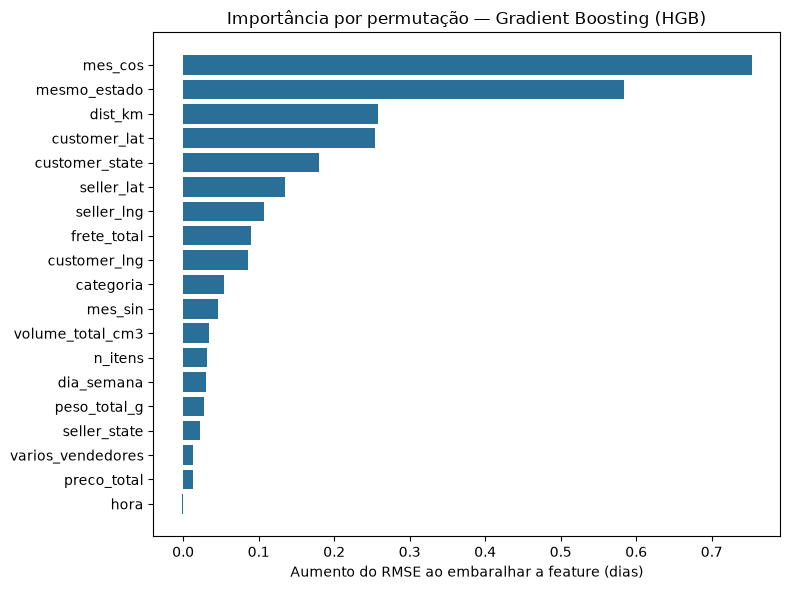

In [10]:
# Importância por permutação (variação do RMSE ao embaralhar cada feature), numa amostra do teste.
rng = np.random.RandomState(SEED)
indices = rng.choice(len(X_teste), 6000, replace=False)
importancia = permutation_importance(
    melhor.best_estimator_, X_teste.iloc[indices], y_teste.iloc[indices],
    scoring='neg_root_mean_squared_error', n_repeats=5, random_state=SEED, n_jobs=-1,
)
imp = pd.Series(importancia.importances_mean, index=X_teste.columns).sort_values()
fig, eixo = plt.subplots(figsize=(8, 6))
eixo.barh(imp.index, imp.values, color='#2a6f97')
eixo.set_xlabel('Aumento do RMSE ao embaralhar a feature (dias)')
eixo.set_title(f'Importância por permutação — {melhor_nome}')
fig.tight_layout()
plt.show()

In [11]:
# Erro por faixa de distância e por região do cliente, para o melhor modelo.
analise = X_teste[['dist_km', 'customer_state']].copy()
analise['erro_abs'] = np.abs(residuo)
analise['faixa_dist'] = pd.cut(analise['dist_km'], [0, 100, 500, 1000, 2000, np.inf],
                               labels=['até 100 km', '100–500', '500–1000', '1000–2000', 'mais de 2000'], include_lowest=True)
display(analise.groupby('faixa_dist', observed=True)['erro_abs'].agg(['size', 'mean']).rename(columns={'size': 'pedidos', 'mean': 'MAE'}))

,pedidos,MAE
faixa_dist,,
até 100 km,3684,2.958
100–500,7381,4.288
500–1000,5182,4.888
1000–2000,1911,5.927
mais de 2000,1136,7.127


## 6. Conclusão

**Resultado:** o melhor modelo foi o **Gradient Boosting (`HistGradientBoostingRegressor`)** ajustado com `RandomizedSearchCV`.
No teste ele chegou a RMSE 7,39 dias (R² 0,37) em todos os pedidos e RMSE 6,38 dias (R² 0,43) até 60 dias,
contra 9,31 de prever a média (-21% no RMSE). A otimização de hiperparâmetros deu um ganho pequeno sobre o baseline padrão
da etapa 2 (RMSE 7,47 -> 7,39).

| Modelo | Busca | RMSE teste (todos) | RMSE teste (até 60 dias) | RMSE validação (CV) |
|---|---|---|---|---|
| Gradient Boosting (HGB) | Randomized (25) | **7,39** | **6,38** | 6,39 |
| Random Forest | Randomized (12) | 7,51 | 6,50 | 6,49 |
| KNN | Grid (8) | 7,74 | 6,75 | 6,74 |
| Árvore de decisão | Grid (12) | 7,76 | 6,77 | 6,76 |
| Ridge | Grid (6) | 7,82 | 6,84 | 6,83 |

**O que a busca mostrou**
- **Ridge:** `alpha` quase não importa (RMSE 6,83 até alpha 10), o que indica pouca regularização necessária. O limite do modelo é ser linear.
- **Árvore:** melhora com profundidade 12 e folhas grandes (200 pedidos); com folhas pequenas o erro de treino cai e o de validação não.
- **KNN:** com `weights='distance'` o RMSE de treino cai a 3,96 contra 6,74 na validação: decora os vizinhos. Foi também o mais lento (cerca de 10 min).
- **Random Forest e HGB:** os melhores, com sobreajuste moderado (treino 5,3 e 5,8 contra validação 6,5 e 6,4). O HGB venceu e foi mais rápido que a Random Forest.
- O RMSE de validação (6,39) bate com o do teste até 60 dias (6,38), então a validação cruzada reflete bem o desempenho fora da amostra.

**O que explica o prazo (importância por permutação):** a variável mais importante é **`mes_cos`** (+0,75 dia de RMSE ao embaralhar),
seguida de `mesmo_estado` (0,58), `dist_km` e `customer_lat` (0,26) e `customer_state` (0,18). Frete, peso, volume, preço e `hora` pesam pouco.
Ou seja, **época do ano e localização** dominam, o que combina com a EDA (prazo médio de 15 a 16 dias em jan, fev, nov e dez contra 9 em agosto).

**Limites**
- O teto continua baixo (R² de 0,37 a 0,43): o prazo depende de fatores posteriores à compra (postagem do vendedor, transportadora, eventos externos).
- Os 57 pedidos do teste com mais de 60 dias pesam muito no RMSE; por isso o RMSE "até 60 dias" é bem menor.
- A divisão é aleatória, não temporal. O peso de `mes_cos` pode refletir períodos específicos da base (2017-2018), e não um padrão que se repetiria.
- O prazo estimado da Olist (RMSE 14,97; MAE 12,7) é conservador de propósito e quase sempre acima do prazo real, por isso não é um concorrente justo como previsor pontual.